# Credit Card Default Prediction — Classification (Parts A & B)

**Dataset:** `default_of_credit_card_clients_real.csv`  
**Target:** `default payment next month` (0 = no default, 1 = default)

This notebook implements all ten classification algorithms required by the 23CSE301 Machine Learning Capstone guidelines. Every model uses the same stratified 80:20 split and the same training-only preprocessing pipeline. Random state is set to 42 for reproducibility.

## 1. Imports and reproducibility

In [50]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 2. Load the specified dataset
The loader checks the notebook's current folder, a local `data/` folder, and the standard uploaded-file location. If none is found, update `DATA_PATH` to the CSV location on your computer.

In [53]:
import pandas as pd
import os

TARGET = "default payment next month"

paths = [
    "default_of_credit_card_clients_real.csv",
    "data/default_of_credit_card_clients_real.csv",
    "/mnt/data/default_of_credit_card_clients_real.csv"
]

DATA_PATH = next((p for p in paths if os.path.exists(p)), None)

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)
    df.columns = df.columns.str.strip()

    print("Shape:", df.shape)
    display(df.head())
else:
    print("CSV file not found. Check the file path.")


CSV file not found. Check the file path.


## 3. Dataset audit
Check shape, data types, missing values, duplicates, and target-class distribution before modelling.

In [52]:
print("Dataset shape:", df.shape)
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nTarget distribution:")
display(df[TARGET].value_counts(dropna=False).rename_axis("class").to_frame("count"))
display((df[TARGET].value_counts(normalize=True, dropna=False) * 100).round(2).rename("percentage").to_frame())
if df[TARGET].isna().any():
    raise ValueError("The target contains missing values; inspect and resolve them before training.")


Dataset shape: (30000, 25)


,dtype,missing_values,missing_percent,unique_values
ID,int64,0,0.0,30000
LIMIT_BAL,int64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_0,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


Duplicate rows: 0

Target distribution:


,count
class,
0,23364
1,6636


,percentage
default payment next month,
0,77.88
1,22.12


## 4. Exploratory data analysis (EDA)
The following plots cover the target distribution, distributions of all features, a correlation heatmap, and two feature–target relationships. Use the plots to form observations from the actual output rather than assuming a result in advance.

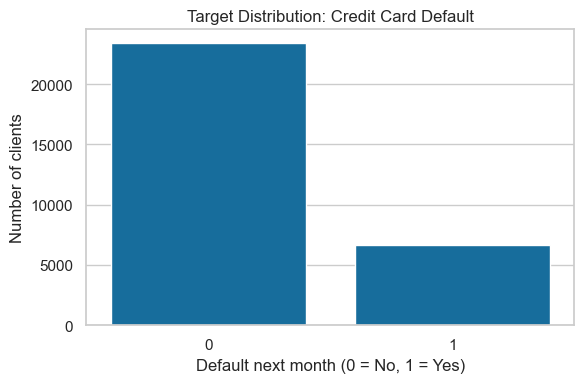

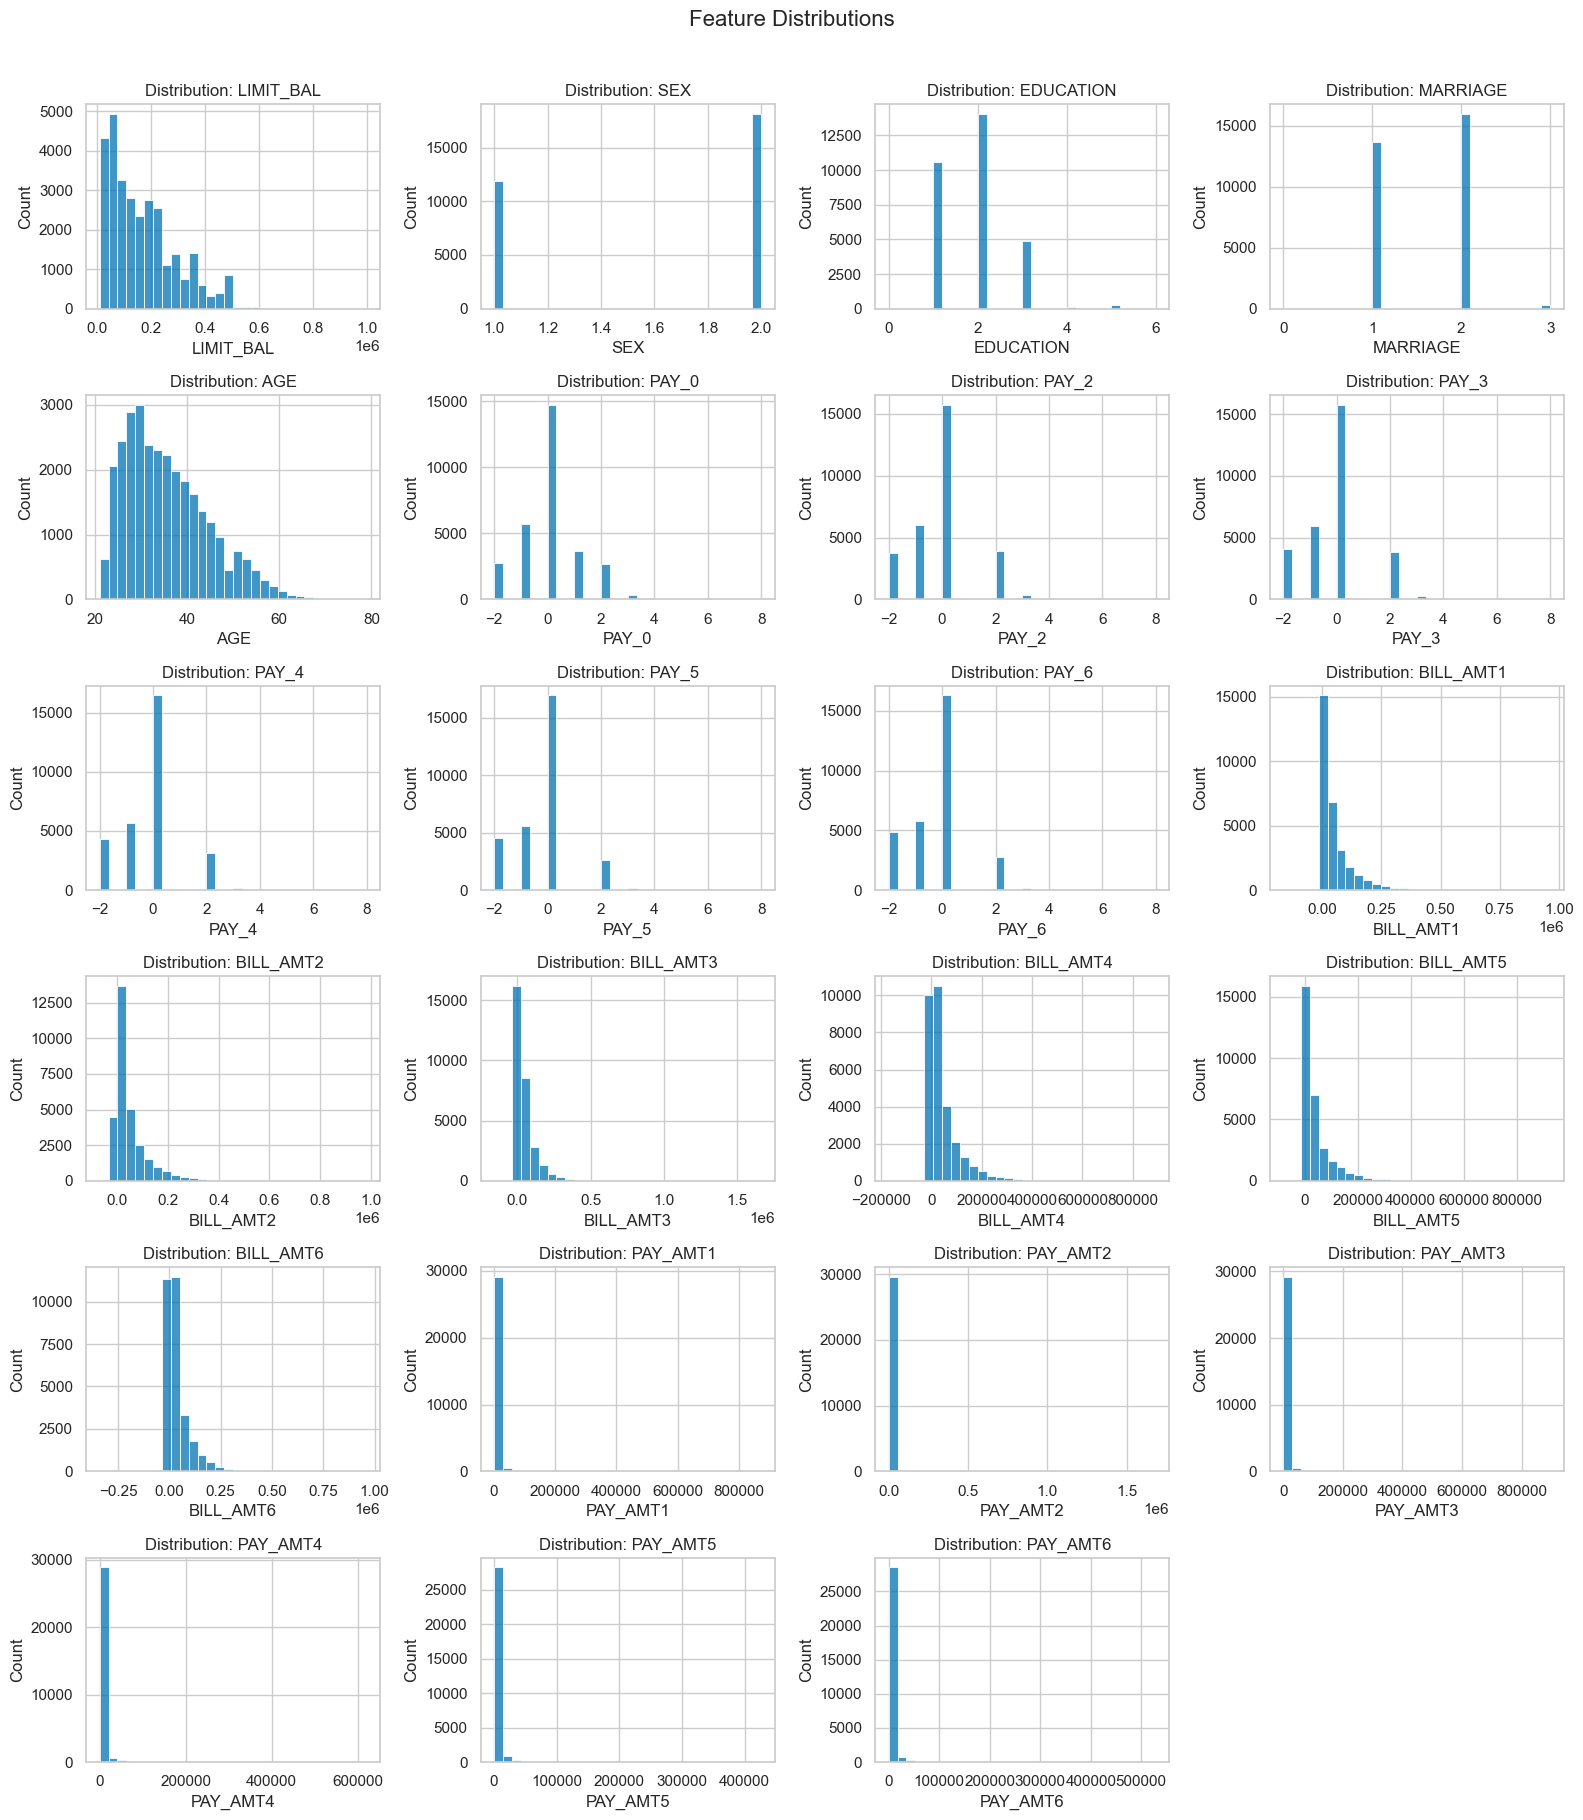

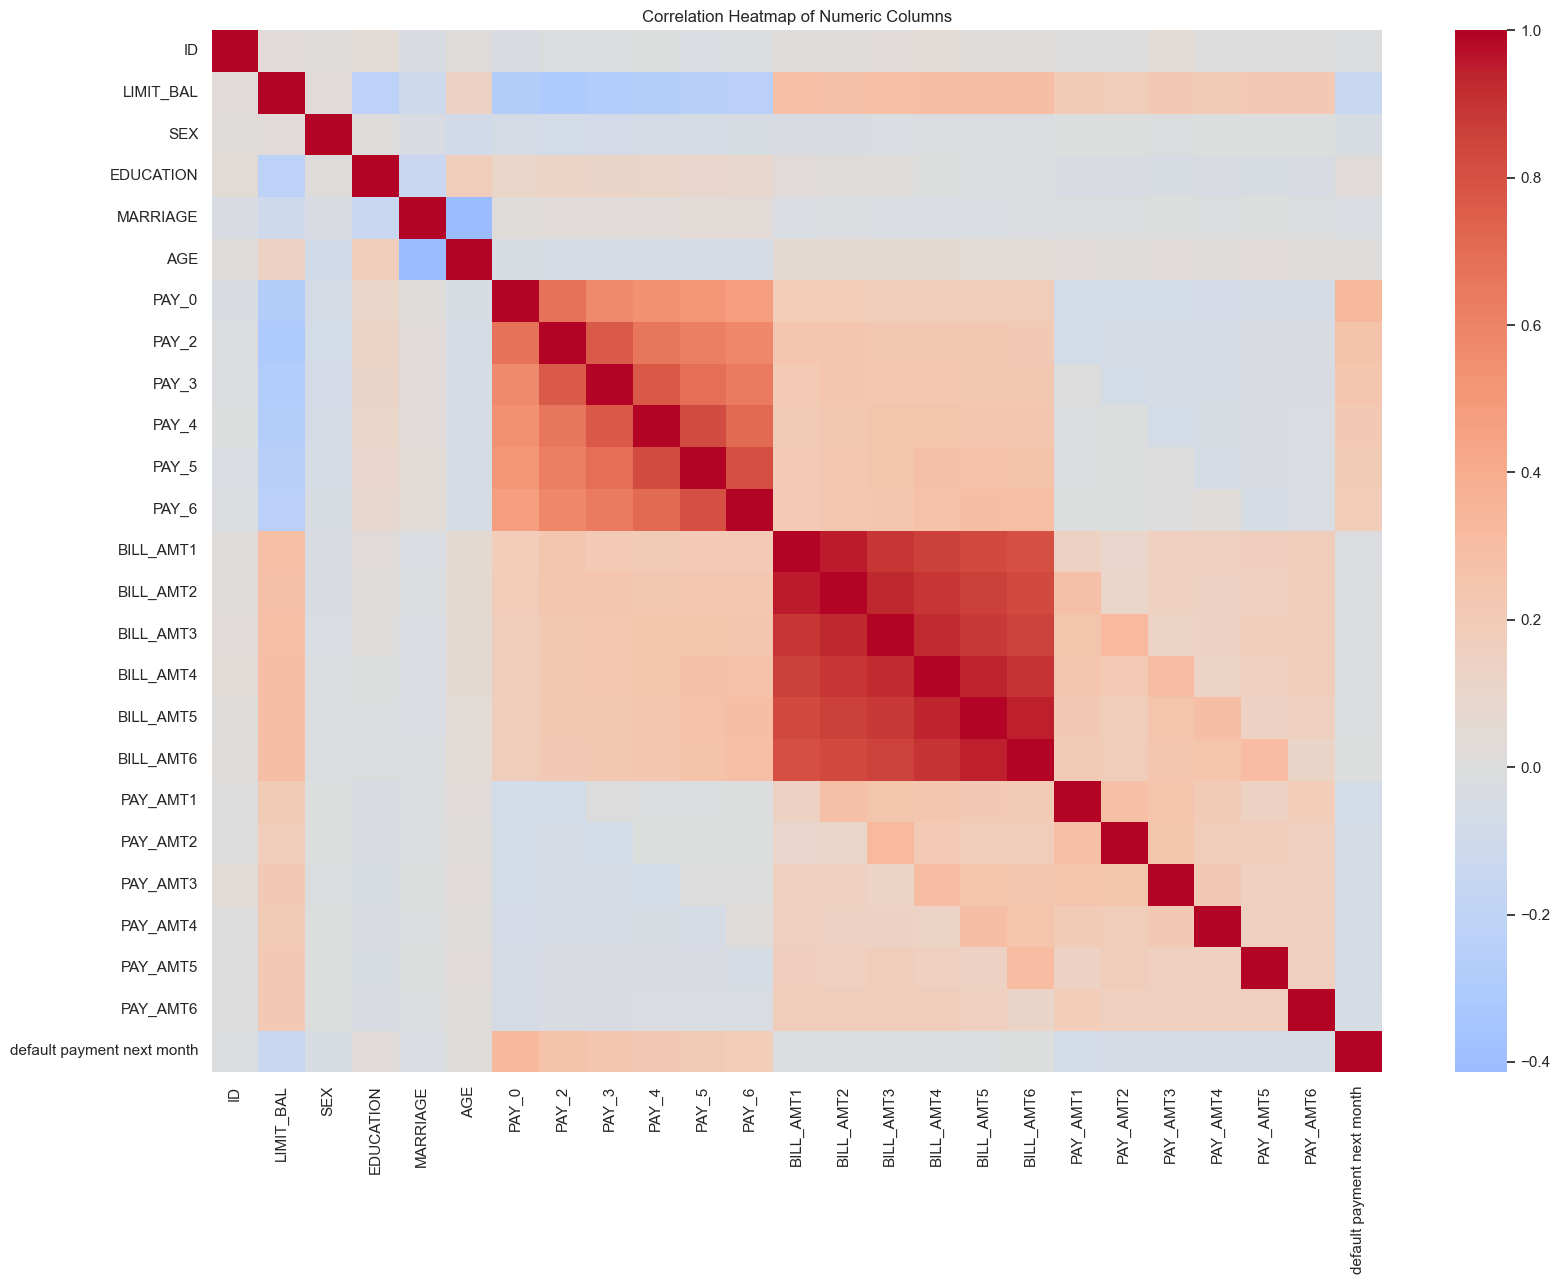

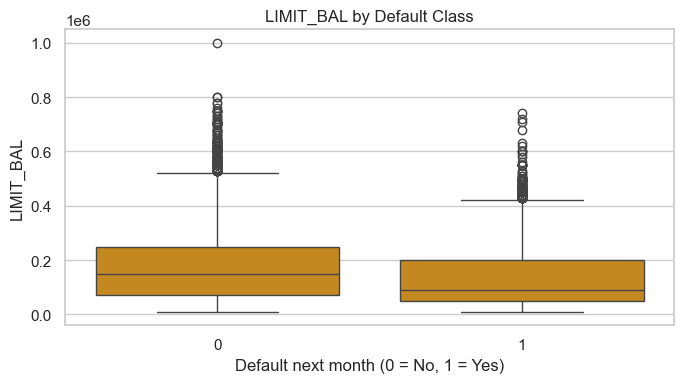

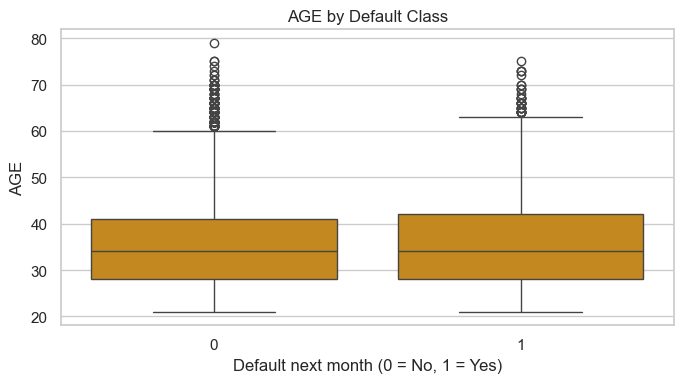

In [54]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, color=sns.color_palette("colorblind")[0])
plt.title("Target Distribution: Credit Card Default")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of clients")
plt.tight_layout()
plt.show()

feature_cols_for_eda = [c for c in df.columns if c != TARGET and c.upper() != "ID"]
ncols = 4
nrows = int(np.ceil(len(feature_cols_for_eda) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.0))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, feature_cols_for_eda):
    sns.histplot(data=df, x=col, bins=30, ax=ax, color=sns.color_palette("colorblind")[0])
    ax.set_title(f"Distribution: {col}")
for ax in axes[len(feature_cols_for_eda):]:
    ax.set_visible(False)
fig.suptitle("Feature Distributions", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(17, 13))
sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()

for feature in ["LIMIT_BAL", "AGE"]:
    if feature in df.columns:
        plt.figure(figsize=(7, 4))
        sns.boxplot(data=df, x=TARGET, y=feature, color=sns.color_palette("colorblind")[1])
        plt.title(f"{feature} by Default Class")
        plt.xlabel("Default next month (0 = No, 1 = Yes)")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()


### EDA observations — complete after reviewing your plots
- **Target distribution:** use the count plot to describe whether the two classes are balanced or imbalanced.
- **Feature distributions:** note skewed monetary features and unusual values visible in the histograms.
- **Correlation heatmap:** identify strongly correlated variables; correlation does not by itself prove causation.
- **Feature–target plots:** compare the distributions across classes and describe only patterns visible in your plots.

## 5. Cleaning and feature engineering
Remove exact duplicate rows, exclude the ID identifier from predictors, and create aggregate billing/payment features. Outliers are counted with the IQR rule for continuous monetary/age variables; these observations are not automatically deleted because unusually high bills or payments may be legitimate financial behaviour. Imputation and scaling are fitted only on the training data inside pipelines.

In [55]:
# Remove exact duplicate records, if present.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", before - len(df))

# Feature engineering: totals and average monthly payment-to-bill ratio.
bill_cols = [c for c in df.columns if c.upper().startswith("BILL_AMT")]
pay_cols = [c for c in df.columns if c.upper().startswith("PAY_AMT")]
if bill_cols:
    df["TOTAL_BILL_AMT"] = df[bill_cols].sum(axis=1)
    df["AVG_BILL_AMT"] = df[bill_cols].mean(axis=1)
if pay_cols:
    df["TOTAL_PAY_AMT"] = df[pay_cols].sum(axis=1)
    df["AVG_PAY_AMT"] = df[pay_cols].mean(axis=1)
if bill_cols and pay_cols:
    df["PAY_TO_BILL_RATIO"] = df["TOTAL_PAY_AMT"] / df["TOTAL_BILL_AMT"].replace(0, np.nan)
    df["PAY_TO_BILL_RATIO"] = df["PAY_TO_BILL_RATIO"].replace([np.inf, -np.inf], np.nan)

print("Engineered features:", [c for c in ["TOTAL_BILL_AMT", "AVG_BILL_AMT", "TOTAL_PAY_AMT", "AVG_PAY_AMT", "PAY_TO_BILL_RATIO"] if c in df.columns])
# IQR outlier audit on selected continuous columns.
continuous_cols = [c for c in ["LIMIT_BAL", "AGE"] + bill_cols + pay_cols if c in df.columns]
outlier_rows = []
for col in continuous_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"Feature": col, "IQR lower bound": low, "IQR upper bound": high,
                         "Outlier count": int(((df[col] < low) | (df[col] > high)).sum())})
display(pd.DataFrame(outlier_rows))
print("Outlier treatment: flagged for audit; not removed automatically because extreme financial values may be valid.")


Exact duplicate rows removed: 0
Engineered features: ['TOTAL_BILL_AMT', 'AVG_BILL_AMT', 'TOTAL_PAY_AMT', 'AVG_PAY_AMT', 'PAY_TO_BILL_RATIO']


,Feature,IQR lower bound,IQR upper bound,Outlier count
0,LIMIT_BAL,-235000.000,525000.000,167
1,AGE,8.500,60.500,272
2,BILL_AMT1,-91739.625,162389.375,2400
3,BILL_AMT2,-88547.500,155538.500,2395
4,BILL_AMT3,-83581.500,146412.500,2469
5,BILL_AMT4,-75942.125,132774.875,2622
6,BILL_AMT5,-70878.250,122831.750,2725
7,BILL_AMT6,-70657.375,121111.625,2693
8,PAY_AMT1,-5009.000,11015.000,2745
9,PAY_AMT2,-5417.500,11250.500,2714


Outlier treatment: flagged for audit; not removed automatically because extreme financial values may be valid.


## 6. Prepare features, target, and one consistent split
`ID` is excluded because it is an identifier. The target is kept separate. The dataset's coded demographic/repayment-status fields are treated as categorical; monetary and age fields are numeric. One-hot encoding, imputation, and scaling are fitted by each pipeline on training data only.

In [56]:
X = df.drop(columns=[TARGET] + [c for c in df.columns if c.upper() == "ID"], errors="ignore").copy()
y = df[TARGET].astype(int).copy()

# The expected target is binary; stop clearly if the provided file differs.
if set(y.dropna().unique()) != {0, 1}:
    raise ValueError(f"Expected binary target labels 0 and 1; found {sorted(y.dropna().unique().tolist())}")

categorical_candidates = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
categorical_features = [c for c in categorical_candidates if c in X.columns]
numeric_features = [c for c in X.columns if c not in categorical_features]
print("Categorical features:", categorical_features)
print("Numeric features:", len(numeric_features))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train target proportions:\n", y_train.value_counts(normalize=True).sort_index().round(3))
print("Test target proportions:\n", y_test.value_counts(normalize=True).sort_index().round(3))

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Numeric features: 19
Train shape: (24000, 28) Test shape: (6000, 28)
Train target proportions:
 default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64
Test target proportions:
 default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64


## 7. Classification algorithms — Part A (five models)
Part A includes Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, and SVC.

In [57]:
part_a_models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(C=1.0, kernel="linear", probability=False, class_weight="balanced", random_state=RANDOM_STATE)
}
print("Part A models:", list(part_a_models))


Part A models: ['Logistic Regression', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Decision Tree', 'Support Vector Machine']


## 8. Classification algorithms — Part B (five models)
Part B uses the **same dataset, target, train/test split, and preprocessing approach** as Part A: Random Forest, AdaBoost, Gradient Boosting, Bagging with a Decision Tree base estimator, and MLP Neural Network.

In [58]:
part_b_models = {
    "Random Forest": RandomForestClassifier(n_estimators=160, max_depth=None, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE),
    "Bagging (Decision Tree)": BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=60, n_jobs=-1, random_state=RANDOM_STATE),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=250, early_stopping=True, random_state=RANDOM_STATE)
}
print("Part B models:", list(part_b_models))


Part B models: ['Random Forest', 'AdaBoost', 'Gradient Boosting', 'Bagging (Decision Tree)', 'MLP Neural Network']


## 9. Train all ten models and evaluate consistently
Metrics required by the guidelines: accuracy, weighted precision, weighted recall, weighted F1, ROC-AUC, and confusion matrix. ROC-AUC is calculated from positive-class probabilities; all models here support `predict_proba`.

In [59]:
all_models = {**part_a_models, **part_b_models}
fitted_models = {}
predictions = {}
probabilities = {}
result_rows = []

for name, classifier in all_models.items():
    model = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])
    print(f"Training {name} ...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = (model.predict_proba(X_test)[:, 1] if hasattr(model.named_steps["classifier"], "predict_proba") else model.decision_function(X_test))
    fitted_models[name] = model
    predictions[name] = y_pred
    probabilities[name] = y_prob
    result_rows.append({
        "Algorithm": name,
        "Track": "Part A" if name in part_a_models else "Part B",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(result_rows).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(results_df.round(4))


Training Logistic Regression ...
Training K-Nearest Neighbors ...
Training Gaussian Naive Bayes ...
Training Decision Tree ...
Training Support Vector Machine ...
Training Random Forest ...
Training AdaBoost ...
Training Gradient Boosting ...
Training Bagging (Decision Tree) ...
Training MLP Neural Network ...


,Algorithm,Track,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MLP Neural Network,Part B,0.8158,0.7977,0.8158,0.7971,0.7754
1,Gradient Boosting,Part B,0.8180,0.8002,0.8180,0.7961,0.7800
2,Bagging (Decision Tree),Part B,0.8155,0.7971,0.8155,0.7961,0.7541
3,Random Forest,Part B,0.8130,0.7933,0.8130,0.7896,0.7627
4,AdaBoost,Part B,0.8128,0.7945,0.8128,0.7816,0.7616
5,K-Nearest Neighbors,Part A,0.8020,0.7786,0.8020,0.7794,0.7123
6,Logistic Regression,Part A,0.7738,0.7847,0.7738,0.7786,0.7588
7,Support Vector Machine,Part A,0.7778,0.7778,0.7778,0.7778,0.7255
8,Decision Tree,Part A,0.7722,0.7838,0.7722,0.7772,0.7403
9,Gaussian Naive Bayes,Part A,0.7902,0.7607,0.7902,0.7302,0.7265


## 10. Confusion matrices and classification reports
Confusion matrices show correct and incorrect predictions for each class. Class 1 is the default class, so pay attention to its recall as well as overall accuracy.


Logistic Regression — classification report
                precision    recall  f1-score   support

No default (0)       0.87      0.84      0.85      4673
   Default (1)       0.49      0.55      0.52      1327

      accuracy                           0.77      6000
     macro avg       0.68      0.70      0.69      6000
  weighted avg       0.78      0.77      0.78      6000



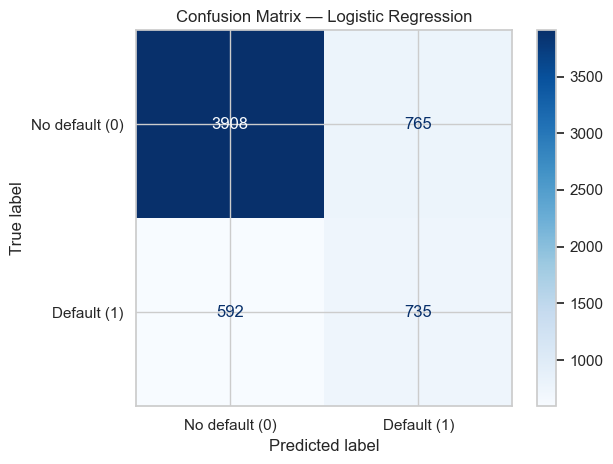


K-Nearest Neighbors — classification report
                precision    recall  f1-score   support

No default (0)       0.83      0.94      0.88      4673
   Default (1)       0.59      0.33      0.42      1327

      accuracy                           0.80      6000
     macro avg       0.71      0.63      0.65      6000
  weighted avg       0.78      0.80      0.78      6000



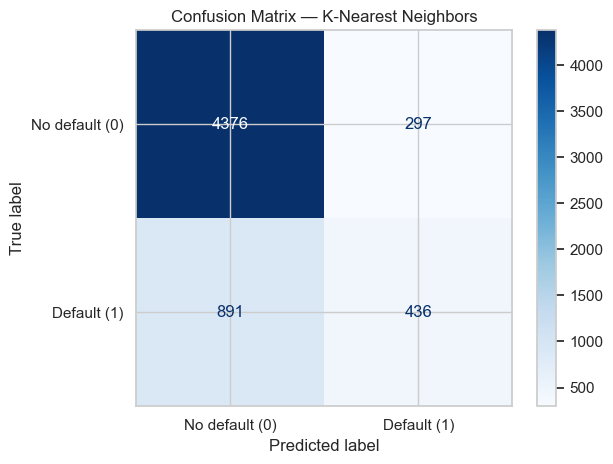


Gaussian Naive Bayes — classification report
                precision    recall  f1-score   support

No default (0)       0.80      0.98      0.88      4673
   Default (1)       0.63      0.12      0.21      1327

      accuracy                           0.79      6000
     macro avg       0.71      0.55      0.54      6000
  weighted avg       0.76      0.79      0.73      6000



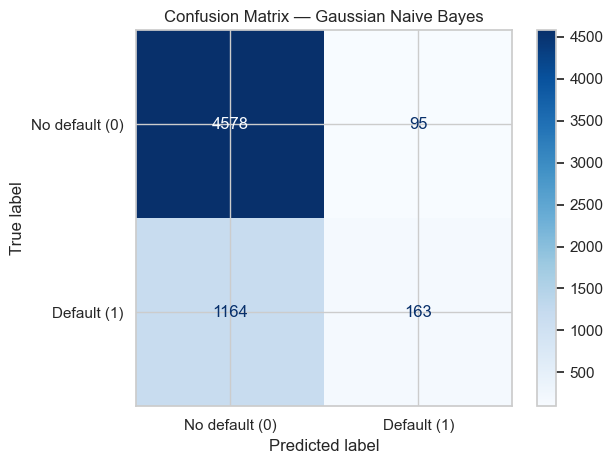


Decision Tree — classification report
                precision    recall  f1-score   support

No default (0)       0.87      0.83      0.85      4673
   Default (1)       0.49      0.55      0.52      1327

      accuracy                           0.77      6000
     macro avg       0.68      0.69      0.68      6000
  weighted avg       0.78      0.77      0.78      6000



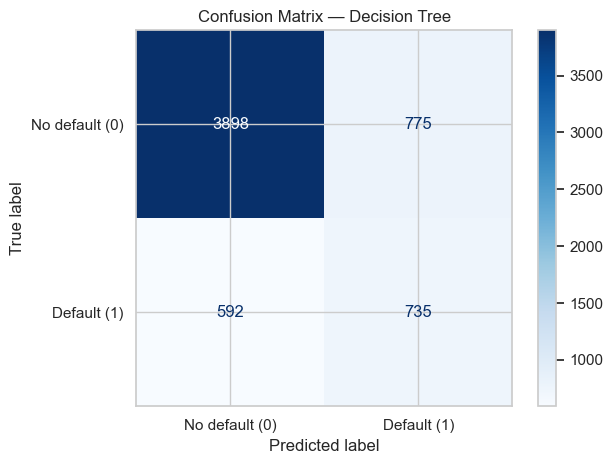


Support Vector Machine — classification report
                precision    recall  f1-score   support

No default (0)       0.86      0.86      0.86      4673
   Default (1)       0.50      0.50      0.50      1327

      accuracy                           0.78      6000
     macro avg       0.68      0.68      0.68      6000
  weighted avg       0.78      0.78      0.78      6000



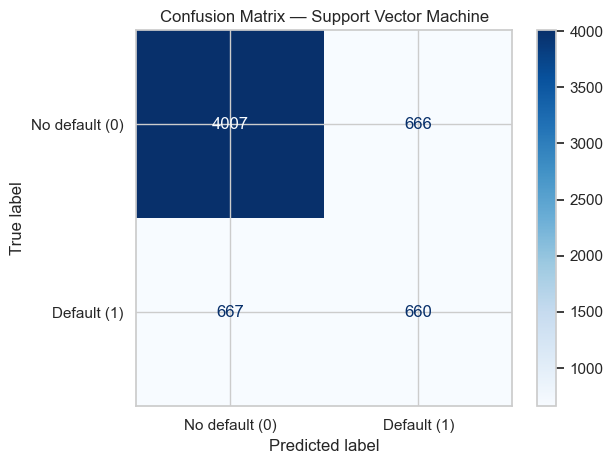


Random Forest — classification report
                precision    recall  f1-score   support

No default (0)       0.83      0.95      0.89      4673
   Default (1)       0.65      0.34      0.44      1327

      accuracy                           0.81      6000
     macro avg       0.74      0.64      0.67      6000
  weighted avg       0.79      0.81      0.79      6000



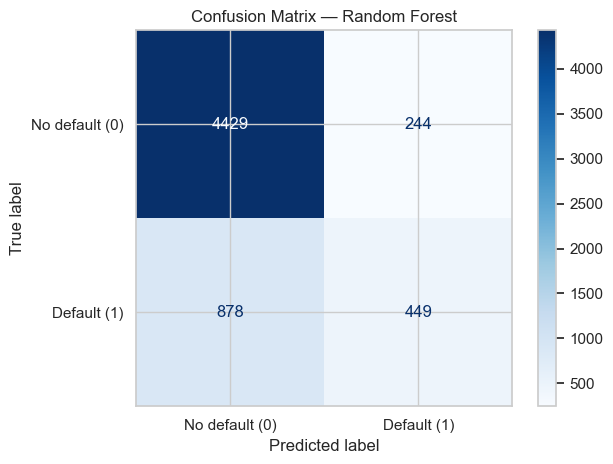


AdaBoost — classification report
                precision    recall  f1-score   support

No default (0)       0.83      0.96      0.89      4673
   Default (1)       0.68      0.29      0.40      1327

      accuracy                           0.81      6000
     macro avg       0.75      0.62      0.65      6000
  weighted avg       0.79      0.81      0.78      6000



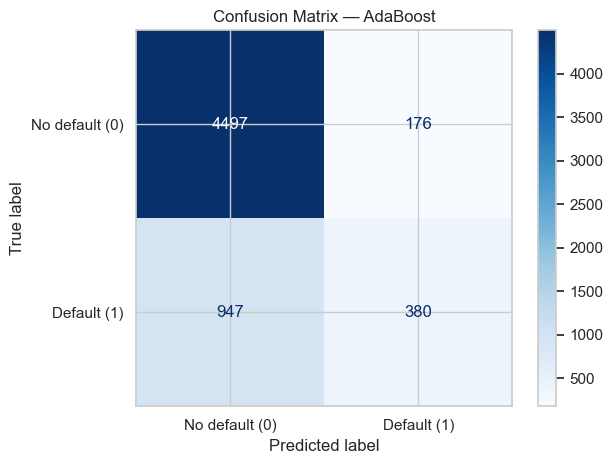


Gradient Boosting — classification report
                precision    recall  f1-score   support

No default (0)       0.84      0.95      0.89      4673
   Default (1)       0.67      0.36      0.46      1327

      accuracy                           0.82      6000
     macro avg       0.75      0.65      0.68      6000
  weighted avg       0.80      0.82      0.80      6000



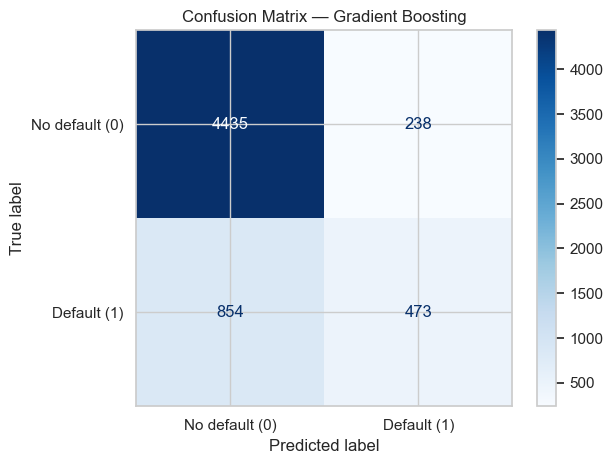


Bagging (Decision Tree) — classification report
                precision    recall  f1-score   support

No default (0)       0.84      0.94      0.89      4673
   Default (1)       0.64      0.37      0.47      1327

      accuracy                           0.82      6000
     macro avg       0.74      0.66      0.68      6000
  weighted avg       0.80      0.82      0.80      6000



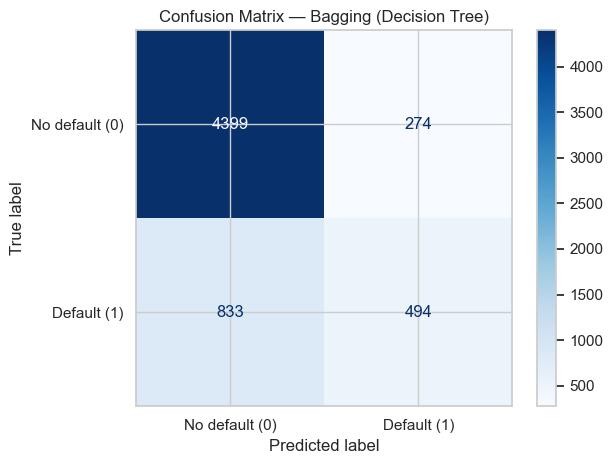


MLP Neural Network — classification report
                precision    recall  f1-score   support

No default (0)       0.84      0.94      0.89      4673
   Default (1)       0.64      0.38      0.48      1327

      accuracy                           0.82      6000
     macro avg       0.74      0.66      0.68      6000
  weighted avg       0.80      0.82      0.80      6000



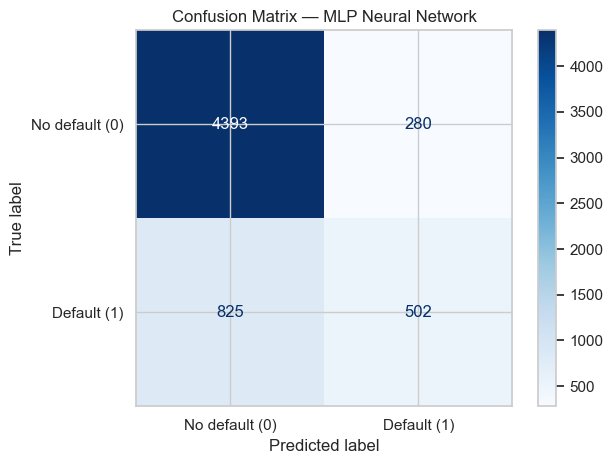

In [60]:
for name in all_models:
    print(f"\n{name} — classification report")
    print(classification_report(y_test, predictions[name], target_names=["No default (0)", "Default (1)"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name],
        display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


## 11. Visual comparison of all ten models

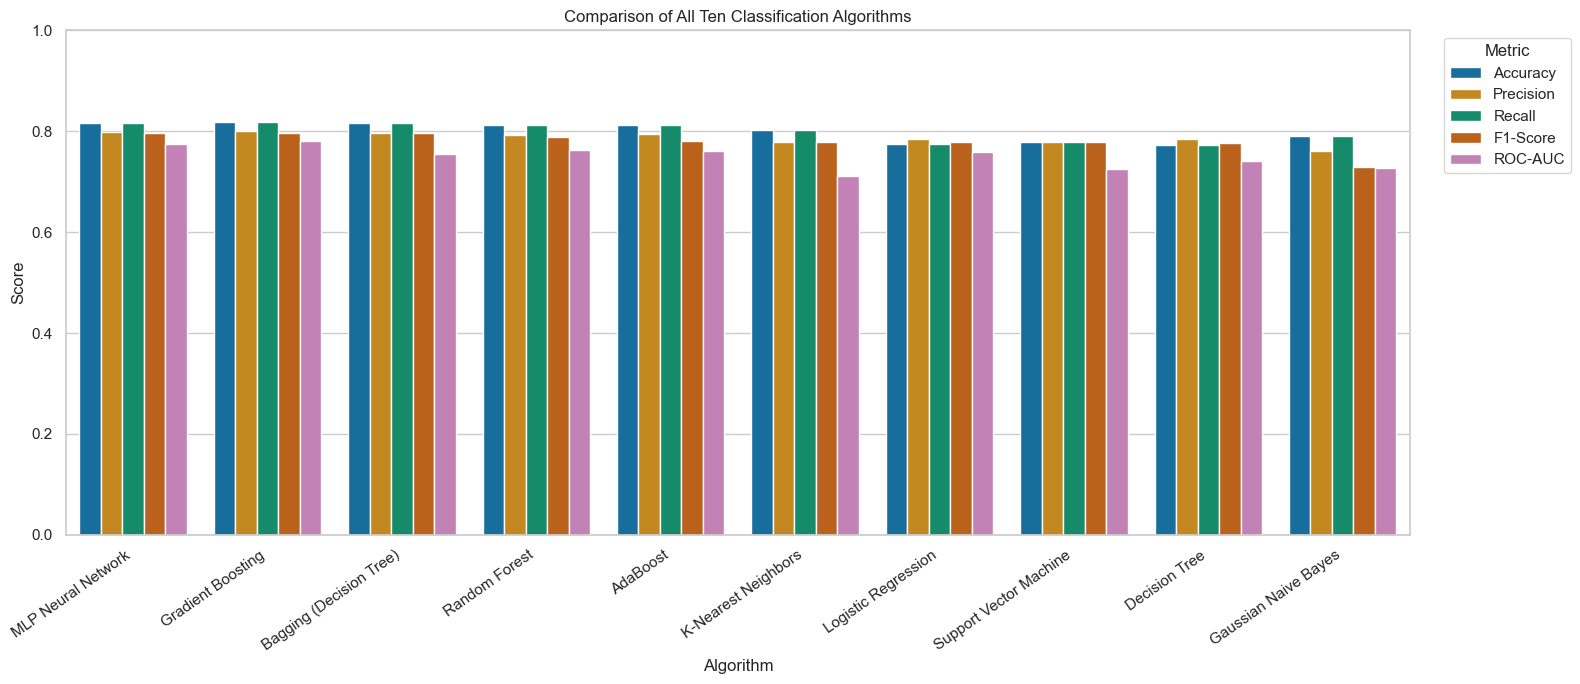

In [61]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_data = results_df.melt(id_vars=["Algorithm", "Track"], value_vars=metrics_to_plot,
                            var_name="Metric", value_name="Score")
plt.figure(figsize=(16, 7))
sns.barplot(data=plot_data, x="Algorithm", y="Score", hue="Metric", palette="colorblind")
plt.title("Comparison of All Ten Classification Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 12. Hyperparameter tuning — Random Forest
A small GridSearchCV searches a limited parameter grid using stratified 3-fold cross-validation. The held-out test set is not used to select hyperparameters. Compare the tuned model against the untuned Random Forest on the same test split.

In [62]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
])
param_grid = {
    "classifier__n_estimators": [100, 160],
    "classifier__max_depth": [None, 12],
    "classifier__min_samples_split": [2]
}
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    rf_pipeline, param_grid=param_grid, scoring="f1_weighted",
    cv=tuning_cv, n_jobs=-1, verbose=1, refit=True
)
grid_search.fit(X_train, y_train)
tuned_rf = grid_search.best_estimator_
tuned_pred = tuned_rf.predict(X_test)
tuned_prob = tuned_rf.predict_proba(X_test)[:, 1]

def metric_row(name, y_true, y_pred, y_score, track="Tuned"):
    return {
        "Algorithm": name, "Track": track,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score)
    }

baseline_rf_row = results_df.loc[results_df["Algorithm"] == "Random Forest"].iloc[0]
tuned_rf_row = metric_row("Tuned Random Forest", y_test, tuned_pred, tuned_prob)
tuning_comparison = pd.DataFrame([baseline_rf_row.to_dict(), tuned_rf_row])
print("Best parameters:", grid_search.best_params_)
print("Best CV weighted F1:", round(grid_search.best_score_, 4))
display(tuning_comparison.round(4))
print("Weighted F1 change (tuned - baseline):", round(tuned_rf_row["F1-Score"] - baseline_rf_row["F1-Score"], 4))


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__max_depth': 12, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 160}
Best CV weighted F1: 0.7965


,Algorithm,Track,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,Part B,0.813,0.7933,0.813,0.7896,0.7627
1,Tuned Random Forest,Tuned,0.795,0.7944,0.795,0.7947,0.7723


Weighted F1 change (tuned - baseline): 0.0051


## 13. Five-fold cross-validation for the two best baseline models
The two highest weighted-F1 models from the initial ten-model comparison are evaluated with stratified 5-fold cross-validation on the training set. This gives a more stable estimate than relying on one split.

In [63]:
top_two_names = results_df.head(2)["Algorithm"].tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in top_two_names:
    cv_scores = cross_val_score(fitted_models[name], X_train, y_train, cv=cv, scoring="f1_weighted", n_jobs=-1)
    cv_rows.append({"Algorithm": name, "CV folds": 5, "Mean weighted F1": cv_scores.mean(), "Std weighted F1": cv_scores.std(),
                    "Fold scores": np.round(cv_scores, 4).tolist()})
display(pd.DataFrame(cv_rows))


,Algorithm,CV folds,Mean weighted F1,Std weighted F1,Fold scores
0,MLP Neural Network,5,0.801498,0.005122,"[0.8065, 0.808, 0.7953, 0.8012, 0.7965]"
1,Gradient Boosting,5,0.799495,0.002187,"[0.801, 0.8026, 0.7979, 0.7996, 0.7964]"


## 14. Final consolidated comparison — all ten required algorithms
The required table contains exactly the ten baseline algorithms. The tuned Random Forest is reported separately above so the consolidated ten-model comparison remains easy to interpret.

In [64]:
final_comparison = results_df[["Algorithm", "Track", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].copy()
final_comparison = final_comparison.sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(final_comparison.round(4))
best_name = results_df.iloc[0]["Algorithm"]
print("Best baseline model by weighted F1:", best_name)
print("Its test metrics:")
display(results_df.loc[results_df["Algorithm"] == best_name].round(4))
print("\nTuned Random Forest best parameters:", grid_search.best_params_)


,Algorithm,Track,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MLP Neural Network,Part B,0.8158,0.7977,0.8158,0.7971,0.7754
1,Gradient Boosting,Part B,0.8180,0.8002,0.8180,0.7961,0.7800
2,Bagging (Decision Tree),Part B,0.8155,0.7971,0.8155,0.7961,0.7541
3,Random Forest,Part B,0.8130,0.7933,0.8130,0.7896,0.7627
4,AdaBoost,Part B,0.8128,0.7945,0.8128,0.7816,0.7616
5,K-Nearest Neighbors,Part A,0.8020,0.7786,0.8020,0.7794,0.7123
6,Logistic Regression,Part A,0.7738,0.7847,0.7738,0.7786,0.7588
7,Support Vector Machine,Part A,0.7778,0.7778,0.7778,0.7778,0.7255
8,Decision Tree,Part A,0.7722,0.7838,0.7722,0.7772,0.7403
9,Gaussian Naive Bayes,Part A,0.7902,0.7607,0.7902,0.7302,0.7265


Best baseline model by weighted F1: MLP Neural Network
Its test metrics:


,Algorithm,Track,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MLP Neural Network,Part B,0.8158,0.7977,0.8158,0.7971,0.7754



Tuned Random Forest best parameters: {'classifier__max_depth': 12, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 160}


## 15. Feature importance (tree-based model)
The Random Forest feature importances are extracted after preprocessing, including one-hot encoded categorical features. These importances indicate how the fitted forest used features; they do not establish causation.

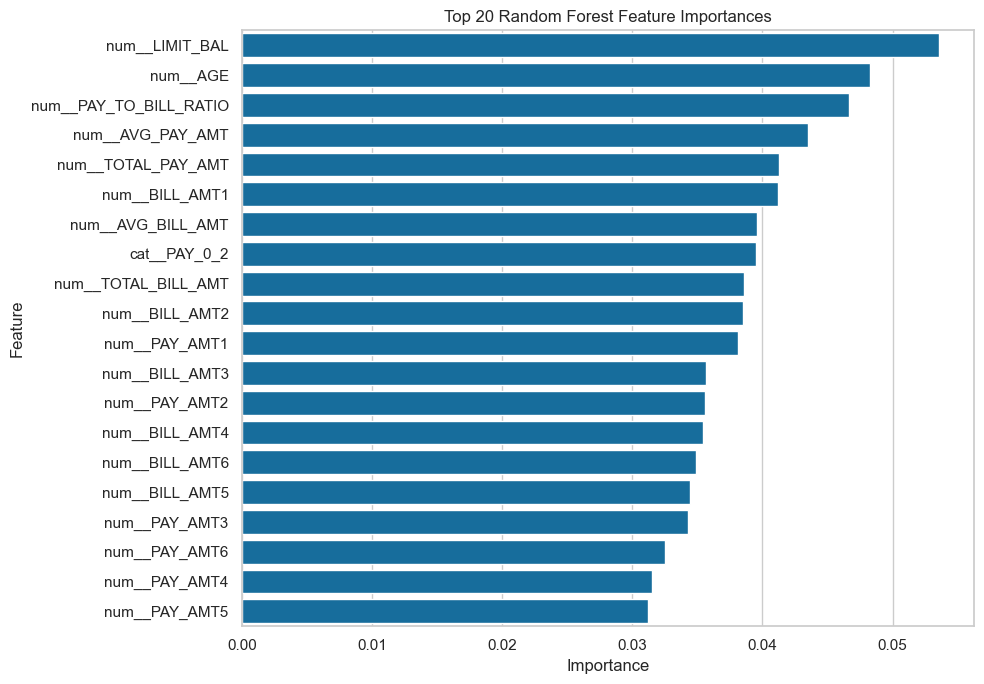

,Feature,Importance
0,num__LIMIT_BAL,0.053583
1,num__AGE,0.048302
2,num__PAY_TO_BILL_RATIO,0.046643
3,num__AVG_PAY_AMT,0.043543
4,num__TOTAL_PAY_AMT,0.041267
5,num__BILL_AMT1,0.041235
6,num__AVG_BILL_AMT,0.039563
7,cat__PAY_0_2,0.039533
8,num__TOTAL_BILL_AMT,0.038567
9,num__BILL_AMT2,0.038481


In [65]:
rf_fitted = fitted_models["Random Forest"]
feature_names = rf_fitted.named_steps["preprocessor"].get_feature_names_out()
importances = rf_fitted.named_steps["classifier"].feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values("Importance", ascending=False).head(20)
plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df, x="Importance", y="Feature", color=sns.color_palette("colorblind")[0])
plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
display(importance_df.reset_index(drop=True))


## 16. Conclusion and reporting checklist

Complete this section after running the notebook and reviewing the actual metrics and plots:
1. State which baseline model achieved the highest weighted F1 and compare its ROC-AUC.
2. Describe the tuned Random Forest's measured change in weighted F1 and other metrics.
3. Discuss the trade-off between detecting defaults (class-1 recall) and avoiding false alarms (precision).
4. Mention limitations: the results reflect this dataset and split; model scores do not guarantee real-world lending outcomes.

**Guideline coverage:** dataset audit; target and feature distributions; correlation heatmap; two feature–target plots; duplicate/missing/outlier checks; engineered features; stratified 80:20 split; training-only preprocessing; five Part A + five Part B models; accuracy/weighted precision/recall/F1/ROC-AUC; confusion matrices; hyperparameter tuning; five-fold cross-validation for the two best baseline models; consolidated ten-model table; feature importance.